In [58]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense

from sklearn.metrics import mean_squared_error

In [59]:
ticket="RELIANCE.NS"
data=yf.download(ticket,period="5y",interval='1d')
data.to_csv('reliance.csv')

[*********************100%***********************]  1 of 1 completed


In [60]:
df=pd.read_csv("reliance.csv",header=0)

In [61]:
df.head()

,Price,Close,High,Low,Open,Volume
0,Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
1,Date,NaN,NaN,NaN,NaN,NaN
2,2021-10-21,1187.7772216796875,1235.5600608138357,1179.0358711096487,1235.2883536749923,20831669
3,2021-10-22,1189.9964599609375,1206.9809106504802,1182.7950231580921,1186.6448064236538,11027475
4,2021-10-25,1178.4019775390625,1213.8202313490058,1163.9992204129485,1213.8202313490058,17198417


In [62]:
df.shape

(1238, 6)

In [63]:
df=df.iloc[2:].copy()

In [64]:
df.head()

,Price,Close,High,Low,Open,Volume
2,2021-10-21,1187.7772216796875,1235.5600608138357,1179.0358711096487,1235.2883536749923,20831669
3,2021-10-22,1189.9964599609375,1206.9809106504802,1182.7950231580921,1186.6448064236538,11027475
4,2021-10-25,1178.4019775390625,1213.8202313490058,1163.9992204129485,1213.8202313490058,17198417
5,2021-10-26,1205.2371826171875,1208.7926167498356,1179.013250231775,1185.3315195274101,9750178
6,2021-10-27,1189.9964599609375,1212.3706072222662,1186.6221641632774,1201.1382490708493,9896298


In [65]:
df.rename(columns={'Price':'Date'},inplace=True)

In [66]:
df.head()

,Date,Close,High,Low,Open,Volume
2,2021-10-21,1187.7772216796875,1235.5600608138357,1179.0358711096487,1235.2883536749923,20831669
3,2021-10-22,1189.9964599609375,1206.9809106504802,1182.7950231580921,1186.6448064236538,11027475
4,2021-10-25,1178.4019775390625,1213.8202313490058,1163.9992204129485,1213.8202313490058,17198417
5,2021-10-26,1205.2371826171875,1208.7926167498356,1179.013250231775,1185.3315195274101,9750178
6,2021-10-27,1189.9964599609375,1212.3706072222662,1186.6221641632774,1201.1382490708493,9896298


In [67]:
df['Date']=pd.to_datetime(df['Date'])

In [68]:
df.set_index('Date', inplace=True)

In [69]:
df.head()

,Close,High,Low,Open,Volume
Date,,,,,
2021-10-21,1187.7772216796875,1235.5600608138357,1179.0358711096487,1235.2883536749923,20831669
2021-10-22,1189.9964599609375,1206.9809106504802,1182.7950231580921,1186.6448064236538,11027475
2021-10-25,1178.4019775390625,1213.8202313490058,1163.9992204129485,1213.8202313490058,17198417
2021-10-26,1205.2371826171875,1208.7926167498356,1179.013250231775,1185.3315195274101,9750178
2021-10-27,1189.9964599609375,1212.3706072222662,1186.6221641632774,1201.1382490708493,9896298


In [70]:
df=df[["Close"]]
df.head()

,Close
Date,
2021-10-21,1187.7772216796875
2021-10-22,1189.9964599609375
2021-10-25,1178.4019775390625
2021-10-26,1205.2371826171875
2021-10-27,1189.9964599609375


In [71]:
df["Close"]=pd.to_numeric(df['Close'],errors="coerce")

In [72]:
df.dropna(inplace=True)

In [73]:
df.to_csv("reliance_v2.csv")

In [74]:
df.head()

,Close
Date,
2021-10-21,1187.777222
2021-10-22,1189.996460
2021-10-25,1178.401978
2021-10-26,1205.237183
2021-10-27,1189.996460


In [75]:
df.shape

(1236, 1)

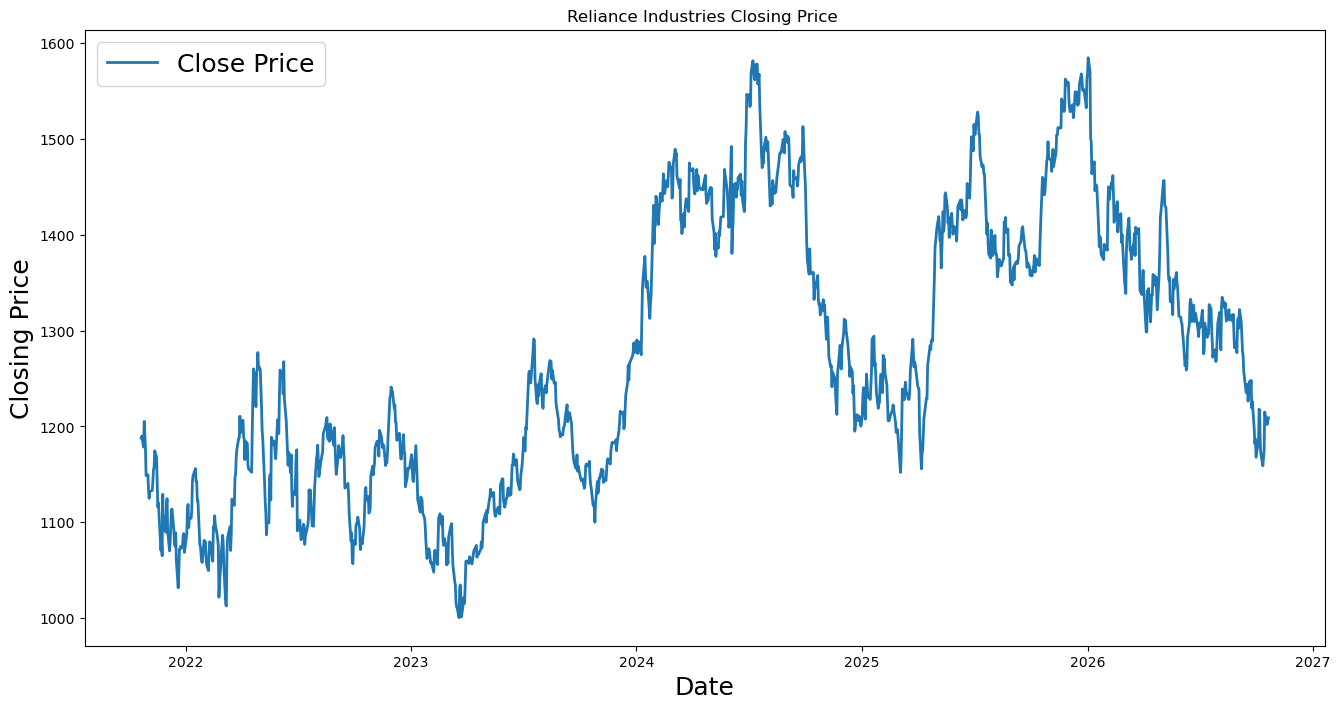

In [77]:
plt.figure(figsize=(16,8))
plt.plot(df['Close'],label="Close Price",linewidth=2)
plt.title("Reliance Industries Closing Price ")
plt.xlabel("Date",fontsize=18)
plt.ylabel("Closing Price",fontsize=18)
plt.legend(fontsize=18)